In [16]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_parquet("data/population.parquet")

# --- variables construites ---
# ancienneté dans l'emploi : "10+ years" -> 10, "< 1 year" -> 0, manquant reste manquant
df["emp_annees"] = df["emp_length"].str.extract(r"(\d+)", expand=False).astype(float)
df.loc[df["emp_length"].str.startswith("<", na=False), "emp_annees"] = 0
# ancienneté du premier crédit au moment de la demande, en années
date_emission   = pd.to_datetime(df["issue_d"], format="%b-%Y")
date_1er_credit = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")
df["anciennete_credit"] = (date_emission - date_1er_credit).dt.days / 365.25
# montant emprunté rapporté au revenu annuel (revenu nul -> manquant, pour éviter la division par 0)
df["montant_sur_revenu"] = df["loan_amnt"] / df["annual_inc"].replace(0, np.nan)

# --- trois familles de variables, trois façons de faire des classes ---
CONTINUES = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc", "revol_bal",
             "revol_util", "total_acc", "anciennete_credit", "montant_sur_revenu"]   # -> 10 tranches
DISCRETES = {"delinq_2yrs": 3, "inq_last_6mths": 4, "pub_rec": 2, "pub_rec_bankruptcies": 2,
             "mort_acc": 6, "emp_annees": 10}       # petits entiers -> plafonnés (ex. "3 ou plus")
CATEGORIELLES = ["home_ownership", "verification_status", "purpose", "addr_state", "application_type"]
TOUTES = CONTINUES + list(DISCRETES) + CATEGORIELLES

# --- découpage HORS DU TEMPS : on apprend sur le passé, on juge sur le futur ---
train = df[df["annee"] <= 2014].copy()
test  = df[df["annee"] == 2015].copy()
print(len(train), "prêts d'entraînement (2010-2014), taux de défaut", round(train["cible"].mean(), 4))
print(len(test),  "prêts de test (2015),            taux de défaut", round(test["cible"].mean(), 4))

329029 prêts d'entraînement (2010-2014), taux de défaut 0.1305
283096 prêts de test (2015),            taux de défaut 0.149


In [17]:
def classes(serie, bornes=None, plafond=None):
    """Transforme une variable en classes (texte). Les manquants forment leur propre classe."""
    if bornes is not None:
        c = pd.cut(serie, bornes).astype(str)
    elif plafond is not None:
        c = serie.clip(upper=plafond).astype(str)
    else:
        c = serie.astype(str)
    return c.where(serie.notna(), "manquant")

def table_woe(classe, y):
    """Pour chaque classe : nombre de prêts, taux de défaut, WoE et contribution à l'IV."""
    t = pd.DataFrame({"classe": classe, "y": y}).groupby("classe")["y"].agg(nb="size", defauts="sum")
    t["sains"] = t["nb"] - t["defauts"]
    p_sains = (t["sains"] + 0.5) / t["sains"].sum()      # + 0.5 : évite log(0) si une classe n'a aucun défaut
    p_def   = (t["defauts"] + 0.5) / t["defauts"].sum()
    t["taux_defaut"] = t["defauts"] / t["nb"]
    t["woe"] = np.log(p_sains / p_def)
    t["iv"]  = (p_sains - p_def) * t["woe"]
    return t

# bornes des tranches = déciles calculés sur le TRAIN (jamais sur le test : ce serait regarder le futur)
BORNES = {}
for v in CONTINUES:
    q = np.unique(train[v].quantile(np.linspace(0, 1, 11)).values)
    q[0], q[-1] = -np.inf, np.inf          # les extrêmes du test tomberont dans les tranches du bord
    BORNES[v] = q

def classer(data, v):
    if v in CONTINUES:
        return classes(data[v], bornes=BORNES[v])
    if v in DISCRETES:
        return classes(data[v], plafond=DISCRETES[v])
    return classes(data[v])

TABLES = {v: table_woe(classer(train, v), train["cible"]) for v in TOUTES}
iv = pd.Series({v: TABLES[v]["iv"].sum() for v in TOUTES}).sort_values(ascending=False)
print(iv.round(3))

TABLES["fico_range_low"][["nb", "taux_defaut", "woe"]].round(3)

fico_range_low          0.142
annual_inc              0.087
dti                     0.048
mort_acc                0.045
montant_sur_revenu      0.043
home_ownership          0.037
inq_last_6mths          0.029
revol_util              0.025
purpose                 0.024
anciennete_credit       0.018
emp_annees              0.018
revol_bal               0.016
addr_state              0.015
total_acc               0.009
verification_status     0.008
loan_amnt               0.006
pub_rec                 0.003
pub_rec_bankruptcies    0.002
delinq_2yrs             0.002
open_acc                0.000
application_type        0.000
dtype: float64


,nb,taux_defaut,woe
classe,,,
"(-inf, 665.0]",55828,0.180,-0.382
"(665.0, 670.0]",28490,0.171,-0.317
"(670.0, 675.0]",25859,0.157,-0.213
"(675.0, 680.0]",25789,0.154,-0.193
"(680.0, 690.0]",45593,0.138,-0.066
"(690.0, 695.0]",20299,0.128,0.019
"(695.0, 705.0]",34490,0.114,0.152
"(705.0, 720.0]",36630,0.095,0.354
"(720.0, 740.0]",26790,0.078,0.567


In [18]:
# on garde les variables utiles (IV >= 0,02)
RETENUES = iv[iv >= 0.02].index.tolist()

def en_woe(data, variables):
    """Remplace chaque valeur par le WoE de sa classe. Classe jamais vue au train -> WoE 0 (neutre)."""
    return pd.DataFrame({v: classer(data, v).map(TABLES[v]["woe"]).fillna(0).astype(float)
                         for v in variables}, index=data.index)

X_train, X_test = en_woe(train, RETENUES), en_woe(test, RETENUES)

logit = LogisticRegression(max_iter=1000)
logit.fit(X_train, train["cible"])
print(pd.Series(logit.coef_[0], index=RETENUES).round(3), "\n")

train["pd_logit"] = logit.predict_proba(X_train)[:, 1]
test["pd_logit"]  = logit.predict_proba(X_test)[:, 1]

def gini(y, score):
    return 2 * roc_auc_score(y, score) - 1

print("Gini train :", round(gini(train["cible"], train["pd_logit"]), 3))
print("Gini test  :", round(gini(test["cible"], test["pd_logit"]), 3))

# l'étalon : le sous-grade de Lending Club (A1 = 0 ... G5 = 34), mesuré sur le même test
ordre = sorted(df["sub_grade"].unique())
test["sous_grade_num"] = test["sub_grade"].map({g: i for i, g in enumerate(ordre)})
print("Gini sous-grade Lending Club :", round(gini(test["cible"], test["sous_grade_num"]), 3), "\n")

print("PD moyenne prédite sur 2015 :", round(test["pd_logit"].mean(), 4))
print("Taux de défaut réel 2015    :", round(test["cible"].mean(), 4))

fico_range_low       -0.838
annual_inc           -0.515
dti                  -0.599
mort_acc             -0.272
montant_sur_revenu   -0.710
home_ownership       -0.372
inq_last_6mths       -1.101
revol_util           -0.146
purpose              -0.967
dtype: float64 

Gini train : 0.305
Gini test  : 0.303
Gini sous-grade Lending Club : 0.357 

PD moyenne prédite sur 2015 : 0.1312
Taux de défaut réel 2015    : 0.149


In [19]:
import lightgbm as lgb

# LightGBM lit directement les variables brutes (pas besoin de WoE) et gère seul les manquants
X_gb_train, X_gb_test = train[TOUTES].copy(), test[TOUTES].copy()
for c in CATEGORIELLES:
    cats = X_gb_train[c].astype("category").cat.categories
    X_gb_train[c] = pd.Categorical(X_gb_train[c], categories=cats)
    X_gb_test[c]  = pd.Categorical(X_gb_test[c].where(X_gb_test[c].isin(cats)), categories=cats)

# 2010-2013 pour apprendre, 2014 pour décider QUAND s'arrêter, 2015 reste intouché
valid = (train["annee"] == 2014).values
gb = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31,
                        min_child_samples=200,               # au moins 200 prêts par feuille : limite le par-cœur
                        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
gb.fit(X_gb_train[~valid], train.loc[~valid, "cible"],
       eval_set=[(X_gb_train[valid], train.loc[valid, "cible"])],
       eval_metric="binary_logloss",
       callbacks=[lgb.early_stopping(100, verbose=False)])   # stop si 100 arbres sans progrès

test["pd_gb"] = gb.predict_proba(X_gb_test)[:, 1]
print("Arbres retenus :", gb.best_iteration_)
print("Gini test LightGBM :", round(gini(test["cible"], test["pd_gb"]), 3))
print("PD moyenne prédite :", round(test["pd_gb"].mean(), 4))

# quelles variables le modèle utilise-t-il le plus ? (gain total apporté par chaque variable)
pd.Series(gb.booster_.feature_importance("gain"), index=TOUTES).sort_values(ascending=False).head(10).round(0)

C:\Users\hugoj\projets\projet-credit\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Arbres retenus : 383
Gini test LightGBM : 0.33
PD moyenne prédite : 0.1297


fico_range_low        36072.0
addr_state            34094.0
annual_inc            23766.0
purpose               13067.0
montant_sur_revenu    12940.0
inq_last_6mths        10088.0
dti                    9871.0
revol_bal              9445.0
revol_util             9325.0
anciennete_credit      7463.0
dtype: float64

In [20]:
SANS_ETAT = [v for v in TOUTES if v != "addr_state"]
X_tr2, X_te2 = X_gb_train[SANS_ETAT], X_gb_test[SANS_ETAT]

gb2 = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=200,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
gb2.fit(X_tr2[~valid], train.loc[~valid, "cible"],
        eval_set=[(X_tr2[valid], train.loc[valid, "cible"])], eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(100, verbose=False)])

test["pd_gb2"] = gb2.predict_proba(X_te2)[:, 1]
print("Arbres :", gb2.best_iteration_)
print("Gini test SANS addr_state :", round(gini(test["cible"], test["pd_gb2"]), 3), " (avec : 0.330)")

C:\Users\hugoj\projets\projet-credit\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Arbres : 381
Gini test SANS addr_state : 0.331  (avec : 0.330)


                Gini     KS  PD moyenne  PSI 2010-14 -> 2015
scorecard      0.303  0.218       0.131                0.000
LightGBM       0.331  0.240       0.130                0.001
sous-grade LC  0.357  0.262         NaN                  NaN
Taux de défaut réel 2015 : 0.149 

Scorecard 
           pd_predite  taux_reel
pd_logit                       
1              0.044      0.043
2              0.068      0.076
3              0.085      0.100
4              0.100      0.117
5              0.115      0.133
6              0.130      0.153
7              0.148      0.174
8              0.169      0.195
9              0.197      0.223
10             0.257      0.277 

LightGBM 
         pd_predite  taux_reel
pd_gb2                       
1            0.036      0.039
2            0.060      0.071
3            0.077      0.091
4            0.093      0.111
5            0.109      0.132
6            0.127      0.153
7            0.147      0.176
8            0.172      0.198
9           

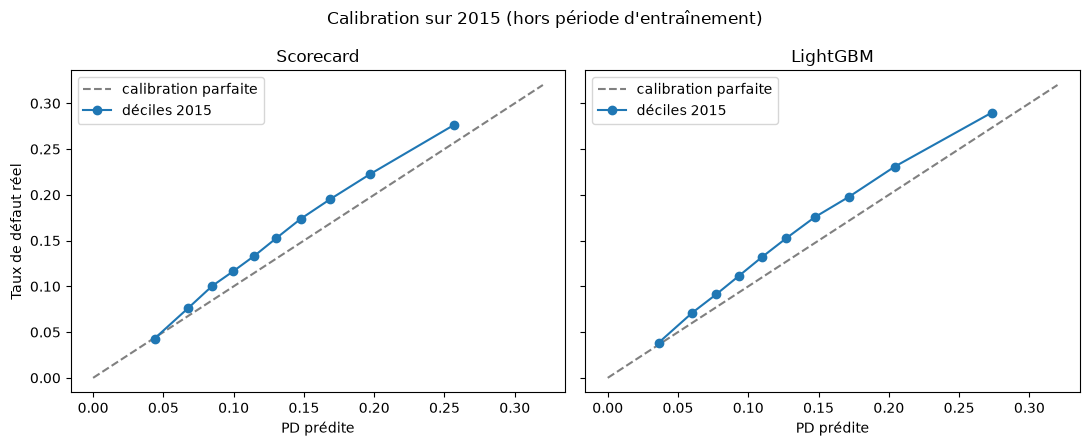

In [21]:
import os
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

def ks(y, score):
    """Écart maximal entre les distributions de score des défauts et des bons payeurs."""
    return ks_2samp(score[y == 1], score[y == 0]).statistic

def psi(reference, recent, n=10):
    """Population Stability Index : la distribution 'recent' a-t-elle bougé par rapport à 'reference' ?"""
    bornes = np.unique(np.quantile(reference, np.linspace(0, 1, n + 1)))
    bornes[0], bornes[-1] = -np.inf, np.inf
    p_ref = pd.Series(pd.cut(reference, bornes)).value_counts(normalize=True, sort=False)
    p_rec = pd.Series(pd.cut(recent, bornes)).value_counts(normalize=True, sort=False)
    return float(((p_rec - p_ref) * np.log(p_rec / p_ref)).sum())

train["pd_gb2"] = gb2.predict_proba(X_tr2)[:, 1]
y = test["cible"].values

bilan = pd.DataFrame({
    "Gini": [gini(y, test["pd_logit"]), gini(y, test["pd_gb2"]), gini(y, test["sous_grade_num"])],
    "KS":   [ks(y, test["pd_logit"].values), ks(y, test["pd_gb2"].values), ks(y, test["sous_grade_num"].values)],
    "PD moyenne": [test["pd_logit"].mean(), test["pd_gb2"].mean(), np.nan],
    "PSI 2010-14 -> 2015": [psi(train["pd_logit"].values, test["pd_logit"].values),
                            psi(train["pd_gb2"].values, test["pd_gb2"].values), np.nan],
}, index=["scorecard", "LightGBM", "sous-grade LC"])
print(bilan.round(3))
print("Taux de défaut réel 2015 :", round(y.mean(), 3), "\n")

# calibration par décile, pour les deux modèles, avec un graphique pour le README
os.makedirs("figures", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (col, nom) in zip(axes, [("pd_logit", "Scorecard"), ("pd_gb2", "LightGBM")]):
    decile = pd.qcut(test[col], 10, labels=False) + 1
    calib = test.groupby(decile).agg(pd_predite=(col, "mean"), taux_reel=("cible", "mean"))
    print(nom, "\n", calib.round(3), "\n")
    ax.plot([0, 0.32], [0, 0.32], "--", color="grey", label="calibration parfaite")
    ax.plot(calib["pd_predite"], calib["taux_reel"], "o-", label="déciles 2015")
    ax.set_title(nom); ax.set_xlabel("PD prédite"); ax.legend()
axes[0].set_ylabel("Taux de défaut réel")
fig.suptitle("Calibration sur 2015 (hors période d'entraînement)")
fig.tight_layout()
fig.savefig("figures/calibration_2015.png", dpi=150)
plt.show()

In [22]:
from scipy.stats import norm

CHAMPION = "pd_logit"        # <- "pd_logit" (scorecard) ou "pd_gb2" (LightGBM), selon ton choix

# --- LGD et EAD : estimées sur les défauts du TRAIN (2010-2014), comme la PD ---
def lgd_ead(data):
    d = data[data["cible"] == 1].copy()
    d["ead_defaut"]  = (d["funded_amnt"] - d["total_rec_prncp"]).clip(lower=0)            # capital encore dû
    d["recup_nette"] = (d["recoveries"] - d["collection_recovery_fee"]).clip(lower=0)      # récupéré, frais déduits
    d = d[d["ead_defaut"] > 0]
    lgd       = 1 - d["recup_nette"].sum() / d["ead_defaut"].sum()
    ratio_ead = d["ead_defaut"].sum() / d["funded_amnt"].sum()     # part du montant initial encore due au défaut
    perte     = d["ead_defaut"].sum() - d["recup_nette"].sum()     # perte réelle en $
    return lgd, ratio_ead, perte

LGD, RATIO_EAD, _ = lgd_ead(train)
print(f"LGD estimée : {LGD:.1%}   |   au défaut, il reste {RATIO_EAD:.1%} du montant initial à rembourser\n")

# --- Perte attendue sur les prêts 2015, et backtest contre la perte réellement constatée ---
test["el"] = test[CHAMPION] * LGD * RATIO_EAD * test["funded_amnt"]
_, _, perte_reelle = lgd_ead(test)
encours = test["funded_amnt"].sum()
print(f"Montant prêté en 2015         : {encours/1e6:,.0f} M$")
print(f"Perte attendue (modèle)       : {test['el'].sum()/1e6:,.0f} M$  ({test['el'].sum()/encours:.2%} du prêté)")
print(f"Perte réelle constatée        : {perte_reelle/1e6:,.0f} M$  ({perte_reelle/encours:.2%} du prêté)\n")

# --- Capital réglementaire, formule IRB 'autre clientèle de détail' (CRR art. 154) ---
def capital_irb(pd_36m, lgd):
    pd_1an = np.maximum(1 - (1 - pd_36m) ** (1 / 3), 0.0005)   # Bâle raisonne à 1 an ; plancher de 0,05 %
    poids = (1 - np.exp(-35 * pd_1an)) / (1 - np.exp(-35))
    R = 0.03 * poids + 0.16 * (1 - poids)                       # corrélation avec le cycle économique
    return lgd * (norm.cdf((norm.ppf(pd_1an) + np.sqrt(R) * norm.ppf(0.999)) / np.sqrt(1 - R)) - pd_1an)

test["K"] = capital_irb(test[CHAMPION].values, LGD)
capital = (test["K"] * test["funded_amnt"]).sum()
print(f"Capital IRB (PD du modèle)    : {capital/1e6:,.0f} M$  ({capital/encours:.2%} du prêté)")

# --- Et si la PD avait été bien calibrée ? (facteur constaté APRÈS COUP sur 2015) ---
facteur = test["cible"].mean() / test[CHAMPION].mean()
K_corrige = capital_irb(np.clip(test[CHAMPION].values * facteur, 0, 0.999), LGD)
capital_corrige = (K_corrige * test["funded_amnt"]).sum()
print(f"Capital IRB (PD × {facteur:.3f})   : {capital_corrige/1e6:,.0f} M$  ({capital_corrige/encours:.2%} du prêté)")

LGD estimée : 89.0%   |   au défaut, il reste 57.4% du montant initial à rembourser

Montant prêté en 2015         : 3,625 M$
Perte attendue (modèle)       : 231 M$  (6.37% du prêté)
Perte réelle constatée        : 274 M$  (7.56% du prêté)

Capital IRB (PD du modèle)    : 368 M$  (10.15% du prêté)
Capital IRB (PD × 1.136)   : 377 M$  (10.39% du prêté)


Tous millésimes 2010-2015 (en %)
        nb_prets  taux_moyen  taux_defaut  rendement_total
grade                                                    
A        141388         7.2          5.5              7.2
B        209730        10.9         11.2              8.9
C        160119        13.9         17.9              8.5
D         75141        17.2         23.4              7.8
E         21081        19.9         28.7              6.0
F          4173        23.8         33.0              5.4
G           493        26.0         40.0              3.1 

Millésime 2015 seul (en %)
        nb_prets  taux_moyen  taux_defaut  rendement_total
grade                                                    
A         70125         6.9          5.4              6.8
B         91754        10.0         11.9              7.3
C         77439        13.2         19.5              6.3
D         32723        16.6         26.2              4.5
E          9446        19.1         32.8              1.6
F       

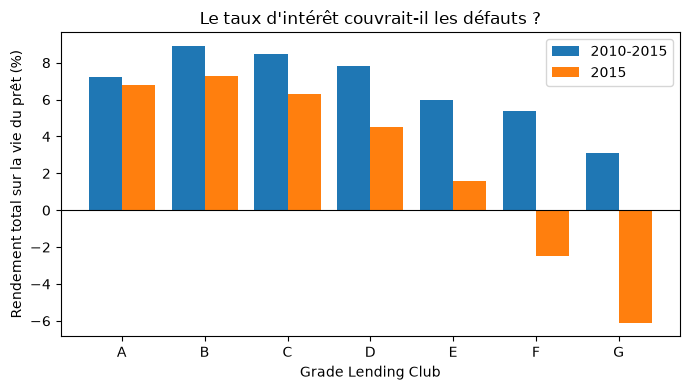

In [23]:
# ÉTAPE 7 — LE TAUX COUVRAIT-IL LE RISQUE ?
# Rendement total = ce que l'investisseur a récupéré sur la vie du prêt (intérêts + capital + récupérations,
# frais de recouvrement déduits), rapporté à ce qu'il a prêté. Positif = il a gagné de l'argent.
def rentabilite(data):
    g = data.groupby("grade").agg(nb_prets=("cible", "size"), taux_moyen=("int_rate", "mean"),
                                  taux_defaut=("cible", "mean"), prete=("funded_amnt", "sum"),
                                  rembourse=("total_pymnt", "sum"), frais=("collection_recovery_fee", "sum"))
    g["taux_defaut"] = g["taux_defaut"] * 100
    g["rendement_total"] = ((g["rembourse"] - g["frais"]) / g["prete"] - 1) * 100
    return g[["nb_prets", "taux_moyen", "taux_defaut", "rendement_total"]].round(1)

tous = rentabilite(df)
annee_2015 = rentabilite(df[df["annee"] == 2015])
print("Tous millésimes 2010-2015 (en %)\n", tous, "\n")
print("Millésime 2015 seul (en %)\n", annee_2015)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(tous))
ax.bar(x - 0.2, tous["rendement_total"], 0.4, label="2010-2015")
ax.bar(x + 0.2, annee_2015["rendement_total"], 0.4, label="2015")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(tous.index)
ax.set_xlabel("Grade Lending Club"); ax.set_ylabel("Rendement total sur la vie du prêt (%)")
ax.set_title("Le taux d'intérêt couvrait-il les défauts ?"); ax.legend()
fig.tight_layout(); fig.savefig("figures/rendement_par_grade.png", dpi=150); plt.show()